____
__Universidad Tecnológica Nacional, Buenos Aires__<br/>
__Ingeniería Industrial__<br/>
__Cátedra de Ciencia de Datos - Curso I5521__<br/>
__Trabajo Práctico Final - Alumna: Melisa Mayrata__
____
# TP Final - Telco Churn
# Machine Learning

**Objetivo: predecir si un cliente se va a ir de la compañía (Churn = 1) o no (Churn = 0).**

Pasos:
1. Separar train y test.
2. Armar el preprocesamiento con `Pipeline` y `ColumnTransformer` (para no tener data leakage).
3. Entrenar un **baseline** y después varios modelos con `GridSearchCV` y validación cruzada.
4. Comparar los modelos, elegir el mejor y evaluarlo en test (AUC, matriz de confusión, sensibilidad y especificidad).
5. Elegir el umbral de decisión según los costos (como en el notebook "Cuando el accuracy nos miente").
6. Aplicar **PCA** (reducción de la dimensionalidad) y volver a predecir.

# Librerías

In [1]:
# Datos
import pandas as pd
import numpy as np
# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns
# Scikit-learn: preprocesamiento y workflow (clase de Pipelines)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
# Modelos vistos en clase
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
# Métricas
from sklearn.metrics import roc_curve, auc, roc_auc_score, accuracy_score, confusion_matrix, precision_score, f1_score
# Otros
import warnings
warnings.filterwarnings('ignore')
import os
os.makedirs('figuras', exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Dataset

In [2]:
# Cargamos el dataset que dejamos limpio en el notebook 2
df = pd.read_csv('telco_churn_limpio.csv')
print(f'Shape: {np.shape(df)}')
df.head(3)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,NaN,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,NaN,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34.0,Yes,No,NaN,Yes,No,Yes,No,No,No,One year,No,Mailed check,55.57,1889.50,0
2,3668-QPYBK,Male,No,No,No,2.0,Yes,No,NaN,Yes,NaN,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


In [3]:
# Definimos las variables de entrenamiento (features) y el objetivo (target)
numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']
categoricas = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
               'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
               'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
features = numericas + categoricas   # customerID no entra porque es un identificador
target = 'Churn'

X = df[features]
y = df[target]
print('Features:', len(features))
print(y.value_counts())

Features: 19
Churn
0    5174
1    1869
Name: count, dtype: int64


# Paso 1: Split train y test

Queremos saber si el modelo **generaliza**, o sea, si predice bien clientes que nunca vio. Si lo evaluamos con los mismos datos con los que entrenó, solo estamos midiendo si los memorizó (overfitting). Por eso separamos un **20% para test**, que no tocamos hasta el final.

Usamos `stratify=y` para que train y test tengan el mismo porcentaje de churn (26,5%). Como el dataset está desbalanceado, si separamos al azar las proporciones podrían quedar distintas. `random_state=42` es la semilla, para que el resultado sea siempre el mismo.

In [4]:
xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('xtrain:', xtrain.shape, '| % churn en train:', round(ytrain.mean() * 100, 1))
print('xtest: ', xtest.shape, '| % churn en test: ', round(ytest.mean() * 100, 1))
print('Faltantes que todavía hay en xtrain:', xtrain.isnull().sum().sum())

xtrain: (5634, 19) | % churn en train: 26.5
xtest:  (1409, 19) | % churn en test:  26.5
Faltantes que todavía hay en xtrain: 8582


**Conclusión:** quedaron 5.634 clientes para entrenar y 1.409 para test, los dos con 26,5% de churn. Todavía hay faltantes en train, que imputamos en el pipeline.

# Paso 2: Preprocesamiento con Pipeline y ColumnTransformer

Si hacemos el preprocesamiento en celdas sueltas (imputar, escalar) es fácil cometer **data leakage**, es decir que información del test se filtre al entrenamiento. Por ejemplo, calcular la mediana con todos los datos. Con un `Pipeline`:
- `.fit()` aprende los parámetros (mediana, media, desvío, categorías) **solo con train**;
- en cada fold de la validación cruzada se vuelve a ajustar solo con la parte de entrenamiento;
- el pipeline entero entra en el `GridSearchCV`.

Usamos un ColumnTransformer porque las numéricas y las categóricas necesitan pasos distintos: a las numéricas les completamos los faltantes con la mediana y las estandarizamos; a las categóricas les completamos los faltantes con la moda y les hacemos one-hot encoding.

In [5]:
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

# Se paralelizan: cada transformer con SU lista de columnas
preprocessor = ColumnTransformer([
    ('num', num_transformer, numericas),
    ('cat', cat_transformer, categoricas)])

# probamos cómo queda la matriz de train después del preprocesamiento
xtrain_transformed = preprocessor.fit_transform(xtrain)
print('Shape de xtrain después del preprocesamiento:', xtrain_transformed.shape)

Shape de xtrain después del preprocesamiento: (5634, 46)


**Conclusión:** las 19 variables pasaron a ser **46 features** (3 numéricas + 43 dummies). Hay información repetida: por ejemplo, `OnlineSecurity_No internet service` es igual a `InternetService_No` y a las otras 5 columnas de "No internet service". Esto lo retomamos en el PCA.

# Paso 3: ¿Con qué métrica comparamos los modelos?

**Matriz de confusión** (positivo = se va):

| | Predice que se queda | Predice que se va |
|---|---|---|
| **Se queda** | TN | FP (falsa alarma) |
| **Se va** | FN (no lo detectamos) | TP |

- **Accuracy** = (TP+TN)/N. **No sirve con desbalance**: decir que nadie se va da 73,5%.
- **Sensibilidad (recall)** = TP/(TP+FN): de los que se van, ¿cuántos detectamos?
- **Especificidad** = TN/(TN+FP): de los que se quedan, ¿cuántos clasificamos bien?
- **Precisión** = TP/(TP+FP): de los que marcamos como "se va", ¿cuántos se iban de verdad?
- **AUC-ROC**: la curva ROC grafica sensibilidad vs (1 − especificidad) para todos los umbrales posibles. El área bajo la curva es la probabilidad de que el modelo le dé más riesgo a un cliente que se va que a uno que se queda. Vale 0,5 si es al azar y 1 si es perfecto. **No depende del umbral ni del desbalance**, por eso **es la métrica que usamos para elegir modelos** (`scoring='roc_auc'`).

**Validación cruzada:** para elegir los hiperparámetros no podemos usar el test. Usamos **5-fold cross validation sobre train**: se divide train en 5 partes, se entrena con 4 y se valida con la que queda, rotando. Usamos `StratifiedKFold` con `shuffle=True` para que cada fold tenga 26,5% de churn y que los folds no dependan del orden del archivo.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# tabla donde vamos guardando los resultados de cada modelo

# Paso 4: Entrenamos los modelos
**4.0 Baseline (modelo trivial)**
Primero entrenamos un modelo simple para tener un **score de referencia**. El `DummyClassifier` no mira las features: le asigna a todos los clientes la misma probabilidad (26,5%). Cualquier modelo que sirva tiene que superarlo.

In [7]:
pipe_dummy = Pipeline([('preprocessor', preprocessor), ('clf', DummyClassifier(strategy='prior'))])
CV_dummy = GridSearchCV(pipe_dummy, param_grid={}, cv=cv, scoring='roc_auc')
CV_dummy.fit(xtrain, ytrain)
print('AUC en validación cruzada:', round(CV_dummy.best_score_, 4))
print('Accuracy en test (prediciendo siempre "no se va"):', round(accuracy_score(ytest, CV_dummy.predict(xtest)), 3))

AUC en validación cruzada: 0.5
Accuracy en test (prediciendo siempre "no se va"): 0.735


**Conclusión:** el baseline tiene AUC = 0,5 (no distingue nada) pero **73,5% de accuracy**. Eso confirma que la accuracy nos puede engañar.

**4.1 Regresión Logística**
Se busca entrenar una regresión logística dentro del pipeline y buscar con `GridSearchCV` (5-fold, scoring AUC) el mejor valor de `C` (probamos de 0,001 a 100) y si conviene usar `class_weight='balanced'` o no.

In [8]:
pipe_lr = Pipeline([('preprocessor', preprocessor), ('clf', LogisticRegression(max_iter=5000))])
param_grid = {'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
              'clf__class_weight': [None, 'balanced']}
CV_lr = GridSearchCV(pipe_lr, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
CV_lr.fit(xtrain, ytrain)
print('Mejores hiperparámetros:', CV_lr.best_params_)
print('Mejor AUC en validación cruzada:', round(CV_lr.best_score_, 4))

Mejores hiperparámetros: {'clf__C': 10, 'clf__class_weight': None}
Mejor AUC en validación cruzada: 0.8385


**Conclusión:** el mejor resultado fue con **C = 10** (poca regularización) y sin `class_weight`, con **AUC ≈ 0,839** en validación. Muy por encima del baseline. Que no haga falta regularizar mucho tiene sentido: hay muchos datos (5.634) para pocas features (46). 

**4.2 KNN**
Se busca entrenar un KNN dentro del pipeline, con las variables ya escaladas por el preprocesamiento, y buscar con `GridSearchCV` la cantidad de vecinos `k` (15, 51, 101, 151 y 201) y si conviene darle más peso a los vecinos más cercanos (`weights='distance'`).

In [9]:
pipe_knn = Pipeline([('preprocessor', preprocessor), ('clf', KNeighborsClassifier())])
param_grid = {'clf__n_neighbors': [15, 51, 101, 151, 201],
              'clf__weights': ['uniform', 'distance']}
CV_knn = GridSearchCV(pipe_knn, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
CV_knn.fit(xtrain, ytrain)
print('Mejores hiperparámetros:', CV_knn.best_params_)
print('Mejor AUC en validación cruzada:', round(CV_knn.best_score_, 4))

Mejores hiperparámetros: {'clf__n_neighbors': 101, 'clf__weights': 'uniform'}
Mejor AUC en validación cruzada: 0.8299


**Conclusión:** KNN necesita **k = 101** vecinos y llega a AUC ≈ 0,830, menos que la logística. Con 46 dimensiones (casi todas 0/1) las distancias son poco informativas: es la **maldición de la dimensionalidad** que vimos en clase.

**4.3 Árbol de decisión**
Se busca entrenar un árbol de decisión y buscar con `GridSearchCV` la profundidad máxima (3, 5, 7 y 10) y el mínimo de clientes por hoja (1, 20, 50 y 100), para controlar que no sobreajuste.

In [10]:
pipe_tree = Pipeline([('preprocessor', preprocessor), ('clf', DecisionTreeClassifier(random_state=42))])
param_grid = {'clf__max_depth': [3, 5, 7, 10],
              'clf__min_samples_leaf': [1, 20, 50, 100]}
CV_tree = GridSearchCV(pipe_tree, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
CV_tree.fit(xtrain, ytrain)
print('Mejores hiperparámetros:', CV_tree.best_params_)
print('Mejor AUC en validación cruzada:', round(CV_tree.best_score_, 4))

Mejores hiperparámetros: {'clf__max_depth': 10, 'clf__min_samples_leaf': 100}
Mejor AUC en validación cruzada: 0.8227


**Conclusión:** el mejor árbol tiene profundidad 10 y **al menos 100 clientes por hoja**, o sea que necesita bastante "poda" para no sobreajustar. El AUC (≈ 0,823) es el más bajo de todos. Esto muestra que un solo árbol tiene mucha varianza.

**4.4 Random Forest**
Se bsuca entrenar un Random Forest de 300 árboles y buscar con `GridSearchCV` la profundidad máxima (6, 10 o sin límite) y el mínimo de clientes por hoja (1, 5 y 20).

In [11]:
pipe_rf = Pipeline([('preprocessor', preprocessor), ('clf', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))])
param_grid = {'clf__max_depth': [6, 10, None],
              'clf__min_samples_leaf': [1, 5, 20]}
CV_rf = GridSearchCV(pipe_rf, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
CV_rf.fit(xtrain, ytrain)
print('Mejores hiperparámetros:', CV_rf.best_params_)
print('Mejor AUC en validación cruzada:', round(CV_rf.best_score_, 4))

Mejores hiperparámetros: {'clf__max_depth': 10, 'clf__min_samples_leaf': 20}
Mejor AUC en validación cruzada: 0.8403


**Conclusión:** con 300 árboles de profundidad 10 el AUC sube a ≈ 0,840, bastante mejor que un solo árbol (0,823). Esto muestra que **el ensamble reduce la varianza**.

**4.5 Gradient Boosting**
Se busca entrenar un Gradient Boosting y buscar con `GridSearchCV` la cantidad de árboles (100 o 200), el `learning_rate` (0,05 o 0,1) y la profundidad de cada árbol (2 o 3). Usamos el de scikit-learn para no tener que instalar librerías extra.

In [12]:
pipe_gb = Pipeline([('preprocessor', preprocessor), ('clf', GradientBoostingClassifier(random_state=42))])
param_grid = {'clf__n_estimators': [100, 200],
              'clf__learning_rate': [0.05, 0.1],
              'clf__max_depth': [2, 3]}
CV_gb = GridSearchCV(pipe_gb, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
CV_gb.fit(xtrain, ytrain)
print('Mejores hiperparámetros:', CV_gb.best_params_)
print('Mejor AUC en validación cruzada:', round(CV_gb.best_score_, 4))

Mejores hiperparámetros: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}
Mejor AUC en validación cruzada: 0.8421


**Conclusión:** con 100 árboles de profundidad 3 y learning rate 0,05 llegamos a **AUC ≈ 0,842**, el mejor hasta ahora.

**4.6 Red neuronal (MLP)**
Se busca entrenar una red neuronal con el `MLPClassifier` de scikit-learn (en vez de PyTorch/TensorFlow, para poder meterla en el pipeline y en el GridSearch) y buscar con `GridSearchCV` la arquitectura (una capa de 16 neuronas, o dos capas de 32 y 16) y la regularización `alpha` (0,001, 0,01, 0,1 y 1). Usamos `early_stopping=True` para que el entrenamiento se corte cuando deja de mejorar en validación.

In [13]:
pipe_mlp = Pipeline([('preprocessor', preprocessor),
                     ('clf', MLPClassifier(max_iter=1000, early_stopping=True, random_state=42))])
param_grid = {'clf__hidden_layer_sizes': [(16,), (32, 16)],
              'clf__alpha': [0.001, 0.01, 0.1, 1]}
CV_mlp = GridSearchCV(pipe_mlp, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
CV_mlp.fit(xtrain, ytrain)
print('Mejores hiperparámetros:', CV_mlp.best_params_)
print('Mejor AUC en validación cruzada:', round(CV_mlp.best_score_, 4))

Mejores hiperparámetros: {'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (32, 16)}
Mejor AUC en validación cruzada: 0.8375


**Conclusión:** la mejor red tiene 2 capas ocultas (32 y 16 neuronas) con alpha = 0,1 y llega a AUC ≈ 0,838, parecido a la logística. Con datos tabulares y pocas features es normal que una red no le gane a los ensambles de árboles.

# Paso 5: Comparación de modelos (validación cruzada)
Juntamos los resultados. Además del promedio del AUC miramos el **desvío entre folds**, que nos dice cuánta incertidumbre tiene cada estimación.

In [14]:
modelos = {'Dummy': CV_dummy, 'Regresión logística': CV_lr, 'KNN': CV_knn, 'Árbol de decisión': CV_tree,
           'Random Forest': CV_rf, 'Gradient Boosting': CV_gb, 'Red neuronal (MLP)': CV_mlp}

tabla_cv = []
auc_folds = {}
for nombre in modelos:
    grid = modelos[nombre]
    i = grid.best_index_
    media = grid.cv_results_['mean_test_score'][i]
    desvio = grid.cv_results_['std_test_score'][i]
    tabla_cv.append([nombre, round(media, 4), round(desvio, 4)])
    auc_folds[nombre] = [grid.cv_results_['split' + str(k) + '_test_score'][i] for k in range(5)]

tabla_cv = pd.DataFrame(tabla_cv, columns=['Modelo', 'AUC CV (media)', 'AUC CV (desvío)'])
tabla_cv = tabla_cv.sort_values('AUC CV (media)', ascending=False).reset_index(drop=True)
tabla_cv

,Modelo,AUC CV (media),AUC CV (desvío)
0,Gradient Boosting,0.8421,0.0122
1,Random Forest,0.8403,0.0099
2,Regresión logística,0.8385,0.0125
3,Red neuronal (MLP),0.8375,0.0119
4,KNN,0.8299,0.0119
5,Árbol de decisión,0.8227,0.0143
6,Dummy,0.5000,0.0000


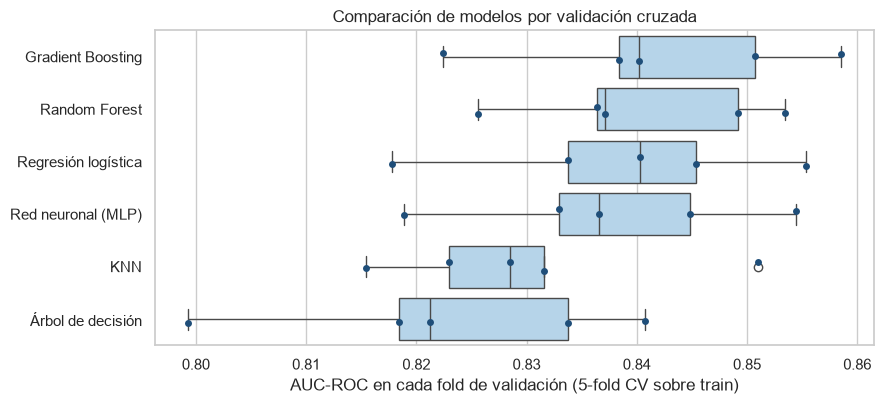

In [15]:
orden = [m for m in tabla_cv['Modelo'] if m != 'Dummy']
folds_df = pd.DataFrame(auc_folds)[orden]
plt.figure(figsize=(9, 4.2))
sns.boxplot(data=folds_df, orient='h', color='#aed6f1')
sns.stripplot(data=folds_df, orient='h', color='#1f4e79', size=5)
plt.xlabel('AUC-ROC en cada fold de validación (5-fold CV sobre train)')
plt.title('Comparación de modelos por validación cruzada')
plt.tight_layout()
plt.savefig('figuras/fig6_cv_modelos.png', dpi=150, bbox_inches='tight')
plt.show()

**Conclusiones de la comparación:**
- **Todos los modelos le ganan claramente al baseline** (AUC 0,5): las variables tienen información para predecir el churn.
- **Gradient Boosting es el mejor** (0,842), pero Random Forest (0,840), la logística (0,839) y la red (0,838) quedan muy cerca. **La diferencia entre ellos es menor que el desvío entre folds (~0,012)**, así que en la práctica están empatados.
- El **árbol solo es el peor** (0,823), y Random Forest y Gradient Boosting lo superan. Esto muestra que **los ensambles (bagging y boosting) reducen el error** de un árbol individual.
- Que la regresión logística (un modelo lineal) esté casi igual que los ensambles nos dice que **la mayor parte del problema se puede resolver con un modelo lineal**: las relaciones no lineales que vimos en el EDA aportan, pero poco.

**Elegimos Gradient Boosting** porque tiene el mejor AUC en validación cruzada. Elegimos por CV y **no por test**: si eligiéramos mirando el test, lo estaríamos usando para entrenar.

# Paso 6: Evaluación en test
Ahora sí, usamos el test una sola vez. Para cada modelo calculamos el AUC con `roc_curve` y `auc`, como en clase, y las demás métricas con el umbral de 0,5.

In [16]:
tabla_test = []
probas = {}
for nombre in tabla_cv['Modelo']:
    grid = modelos[nombre]
    yproba = grid.predict_proba(xtest)[:, 1]
    ypred = grid.predict(xtest)
    probas[nombre] = yproba
    fpr, tpr, thresholds = roc_curve(ytest, yproba)
    auc_test = auc(fpr, tpr)
    tn, fp, fn, tp = confusion_matrix(ytest, ypred).ravel()
    tabla_test.append([nombre, round(auc_test, 3), round(accuracy_score(ytest, ypred), 3),
                       round(tp / (tp + fn), 3), round(tn / (tn + fp), 3),
                       round(precision_score(ytest, ypred, zero_division=0), 3), round(f1_score(ytest, ypred), 3)])

tabla_test = pd.DataFrame(tabla_test, columns=['Modelo', 'AUC test', 'Accuracy', 'Sensibilidad',
                                               'Especificidad', 'Precisión', 'F1'])
tabla_test

,Modelo,AUC test,Accuracy,Sensibilidad,Especificidad,Precisión,F1
0,Gradient Boosting,0.847,0.807,0.508,0.915,0.683,0.583
1,Random Forest,0.841,0.801,0.468,0.921,0.681,0.555
2,Regresión logística,0.835,0.796,0.535,0.890,0.637,0.581
3,Red neuronal (MLP),0.836,0.795,0.508,0.899,0.644,0.568
4,KNN,0.825,0.789,0.583,0.864,0.607,0.595
5,Árbol de decisión,0.833,0.794,0.465,0.913,0.659,0.545
6,Dummy,0.500,0.735,0.000,1.000,0.000,0.000


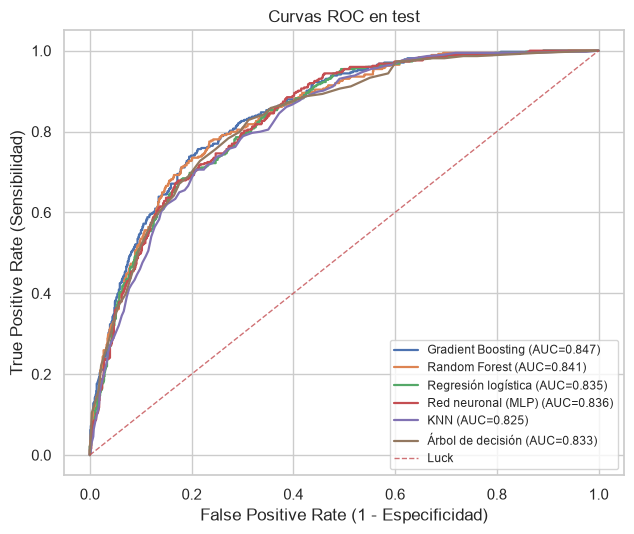

In [17]:
# Curvas ROC de todos los modelos en test
plt.figure(figsize=(6.5, 5.5))
for nombre in orden:
    fpr, tpr, thresholds = roc_curve(ytest, probas[nombre])
    plt.plot(fpr, tpr, lw=1.6, label=nombre + ' (AUC=' + str(round(auc(fpr, tpr), 3)) + ')')
plt.plot([0, 1], [0, 1], linestyle='--', lw=1, color='r', label='Luck', alpha=.8)
plt.xlabel('False Positive Rate (1 - Especificidad)')
plt.ylabel('True Positive Rate (Sensibilidad)')
plt.legend(loc='lower right', fontsize=8.5)
plt.title('Curvas ROC en test')
plt.tight_layout()
plt.savefig('figuras/fig7_roc_test.png', dpi=150, bbox_inches='tight')
plt.show()

**Conclusiones:**
- En test los resultados son **parecidos a los de validación cruzada** (Gradient Boosting 0,847, Random Forest 0,841, la red 0,836, la logística 0,835). Eso significa que la CV estimó bien y que no sobreajustamos al elegir hiperparámetros.
- Las diferencias entre los mejores modelos son muy chicas (menos de 0,015), parecidas al desvío que vimos entre folds en la validación cruzada (~0,012). O sea, **no podemos decir que uno sea claramente mejor que otro**.
- **Con el umbral de 0,5 la sensibilidad es baja** (entre 47% y 58%): se nos escapa casi la mitad de los que se van. La accuracy (~80%) parece buena, pero es solo 6-7 puntos más que el baseline (73,5%). Esto lo arreglamos en el paso siguiente.

# Paso 7: Umbral de decisión según los costos
"Cuando el accuracy nos miente", el umbral de 0,5 es una convención que supone que todos los errores cuestan lo mismo. En churn no es así. Usamos la misma matriz de costos:

| Situación | Costo |
|---|---|
| Se queda y no le ofrecimos nada | 0 |
| Se queda y le ofrecimos la retención | 120 |
| Se va y le ofrecimos la retención | 120 |
| **Se va y no le ofrecimos nada** | **1000** |

Para un cliente con probabilidad $p$ de irse: ofrecer cuesta 120, y no ofrecer cuesta $1000 \cdot p$ en promedio. Conviene ofrecer si $1000\,p > 120$, o sea si $p > \frac{120}{1000} = 0{,}12$.

Este umbral sale de los costos y no de los datos, así que no sobreajustamos el test. Igual lo comprobamos probando todos los umbrales.

In [18]:
# Modelo elegido por validación cruzada
mejor_modelo = CV_gb.best_estimator_
yproba_gb = probas['Gradient Boosting']

# C[actual][accion]: columnas = no oferta / oferta ; filas = se queda / se va (igual que en clase)
C = np.array([[0, 120],
              [1000, 120]])

def costo(y_true, y_pred):
    return C[np.array(y_true), np.array(y_pred)].sum()

ypred_05 = (yproba_gb > 0.5).astype(int)
ypred_012 = (yproba_gb > 0.12).astype(int)

print('Oferta a NADIE:        ', costo(ytest, np.zeros(len(ytest), dtype=int)))
print('Oferta a TODOS:        ', costo(ytest, np.ones(len(ytest), dtype=int)))
print('Modelo umbral 0.5:     ', costo(ytest, ypred_05), '-> clientes contactados:', ypred_05.sum())
print('Modelo umbral 0.12:    ', costo(ytest, ypred_012), '-> clientes contactados:', ypred_012.sum())

Oferta a NADIE:         374000
Oferta a TODOS:         169080
Modelo umbral 0.5:      217360 -> clientes contactados: 278
Modelo umbral 0.12:     124720 -> clientes contactados: 856


Mínimo empírico en umbral 0.12


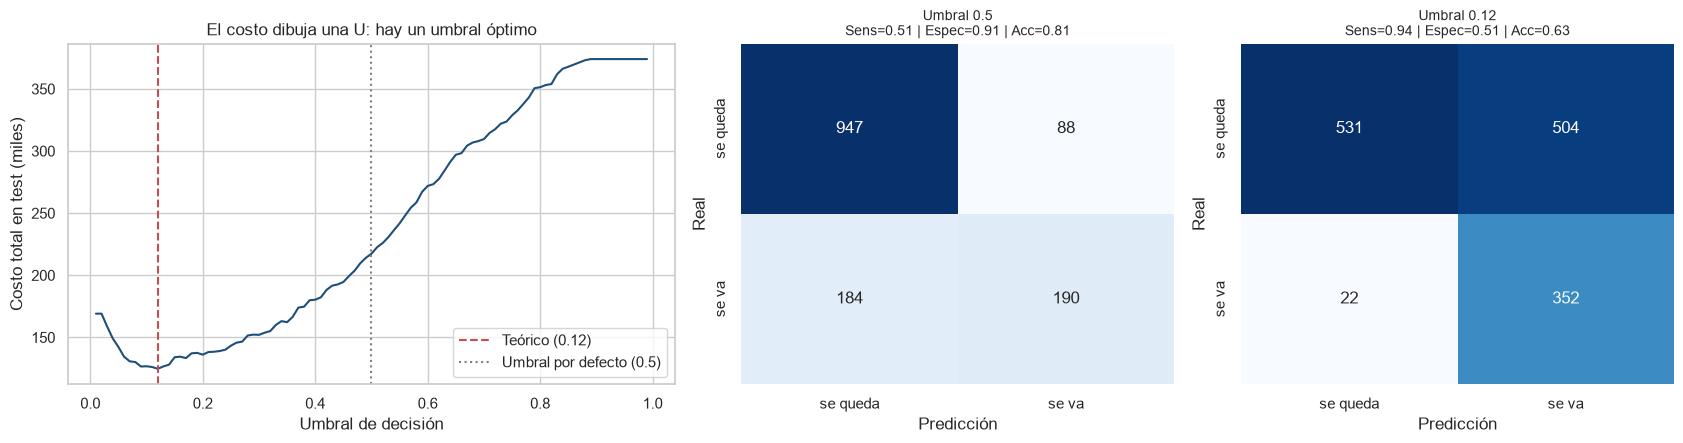

In [19]:
umbrales = np.linspace(0.01, 0.99, 99)
costos = np.array([costo(ytest, (yproba_gb > u).astype(int)) for u in umbrales])
print('Mínimo empírico en umbral', round(umbrales[np.argmin(costos)], 2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1.4, 1, 1]})
ax[0].plot(umbrales, costos / 1000, color='#1f4e79')
ax[0].axvline(0.12, color='r', ls='--', label='Teórico (0.12)')
ax[0].axvline(0.5, color='gray', ls=':', label='Umbral por defecto (0.5)')
ax[0].set_xlabel('Umbral de decisión')
ax[0].set_ylabel('Costo total en test (miles)')
ax[0].set_title('El costo dibuja una U: hay un umbral óptimo')
ax[0].legend()
# matrices de confusión (como en clase, con heatmap)
for j, (u, ypred) in enumerate([(0.5, ypred_05), (0.12, ypred_012)]):
    cm = confusion_matrix(ytest, ypred)
    df_cm = pd.DataFrame(cm, index=['se queda', 'se va'], columns=['se queda', 'se va'])
    sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[j + 1])
    tn, fp, fn, tp = cm.ravel()
    ax[j + 1].set_title('Umbral ' + str(u) + '\nSens=' + str(round(tp / (tp + fn), 2)) + ' | Espec='
                        + str(round(tn / (tn + fp), 2)) + ' | Acc=' + str(round((tp + tn) / cm.sum(), 2)), fontsize=10)
    ax[j + 1].set_xlabel('Predicción')
    ax[j + 1].set_ylabel('Real')
plt.tight_layout()
plt.savefig('figuras/fig8_costos_umbral.png', dpi=150, bbox_inches='tight')
plt.show()

**Conclusiones:**
- **Con el umbral de 0,5** detectamos solo el 51% de los que se van (190 de 374). La campaña cuesta 217 mil, **más que ofrecerle la retención a todos (169 mil)**.
- **Con el umbral de 0,12** la **sensibilidad sube al 94%** (352 de 374). A cambio contactamos a 504 clientes que se iban a quedar: la especificidad baja a 0,51 y la **accuracy baja de 0,81 a 0,63**. Pero el **costo es el más bajo de todos (125 mil)**: ahorramos 249 mil frente a no hacer nada y 44 mil (26%) frente a ofrecer a todos, contactando a 856 clientes en vez de 1.409.
- El mínimo de la curva cae justo en 0,12, como predijo la teoría.
- **Un modelo "peor" en accuracy es mejor para el negocio.** El valor del modelo está en **ordenar a los clientes por riesgo** (eso mide el AUC) para gastar el presupuesto de retención donde más rinde.

# Paso 8: Reducción de la dimensionalidad con PCA
**8.1 Qué se hará en esta etapa**
Se busca aplicar PCA sobre las 46 features que deja el preprocesamiento para ver cuántas componentes hacen falta para explicar el 80%, 90%, 95% y 99% de la varianza, graficar a los clientes en las dos primeras componentes y mirar qué representa cada componente con sus *loadings* (cuánto pesa cada feature original).


- Las 46 features tienen **mucha información repetida**: 7 dummies iguales de "sin internet" y TotalCharges ≈ tenure × MonthlyCharges. La hipótesis de la clase es que los datos "viven" en un subespacio de menor dimensión.
- Con menos dimensiones los modelos son más simples y no hay multicolinealidad, porque las componentes no están correlacionadas entre sí.


- PCA depende de la escala, así que estandarizamos **todas** las features, también las dummies.
- El PCA se ajusta **solo con train**: va dentro del pipeline.
- Es **no supervisado**: busca varianza, no separar las clases.

In [20]:
# Pipeline: preprocesamiento + escalado de todas las features + PCA (sin clasificador, para visualizar)
pipe_pca = Pipeline([('preprocessor', preprocessor),
                     ('scaler', StandardScaler()),
                     ('pca', PCA(random_state=42))])
xpca = pipe_pca.fit_transform(xtrain)
pca = pipe_pca.named_steps['pca']

# obtenemos los autovalores (varianza explicada por cada componente)
eigenvalues = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(eigenvalues)
print('Componentes para explicar el 80% de la varianza:', np.argmax(varianza_acumulada >= 0.80) + 1)
print('Componentes para explicar el 90% de la varianza:', np.argmax(varianza_acumulada >= 0.90) + 1)
print('Componentes para explicar el 95% de la varianza:', np.argmax(varianza_acumulada >= 0.95) + 1)
print('Componentes para explicar el 99% de la varianza:', np.argmax(varianza_acumulada >= 0.99) + 1)

# miramos la varianza de las componentes 21 a 26
print('Varianza explicada de las componentes 21 a 26:', eigenvalues[20:26].round(4))

# a partir de la componente 24 la varianza es 0: con 23 componentes ya tenemos toda la informacion
rango = 23

Componentes para explicar el 80% de la varianza: 13
Componentes para explicar el 90% de la varianza: 16
Componentes para explicar el 95% de la varianza: 19
Componentes para explicar el 99% de la varianza: 21
Varianza explicada de las componentes 21 a 26: [0.0109 0.0016 0.001  0.     0.     0.    ]


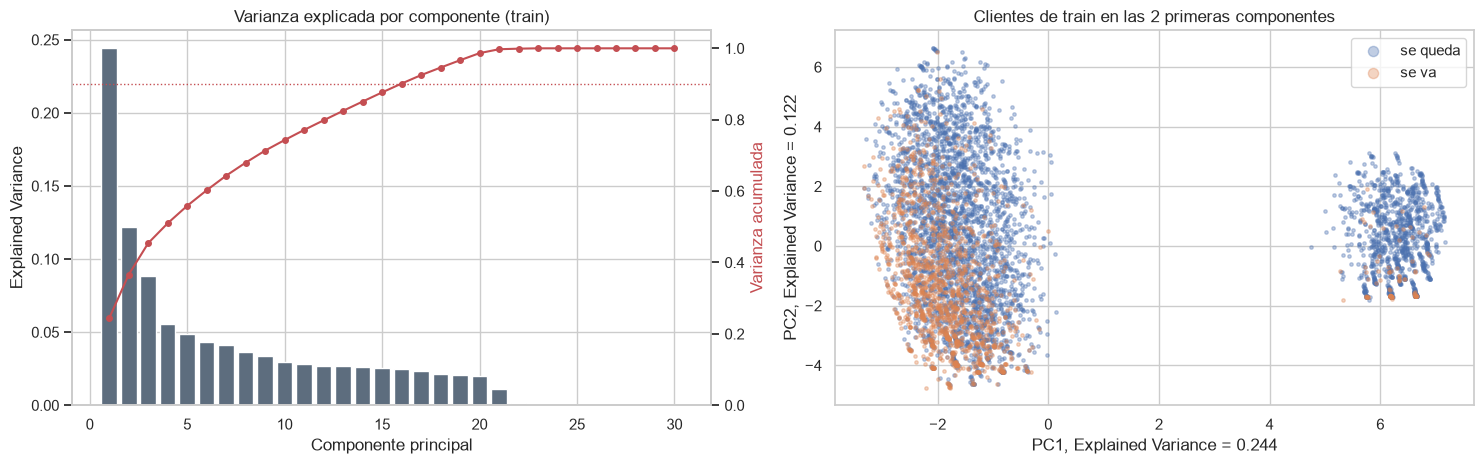

In [21]:
n_comps = 30
fig, ax1 = plt.subplots(1, 2, figsize=(15, 4.8))
components = range(1, n_comps + 1)
# barras de varianza explicada (igual que en el notebook de PCA de clase)
ax1[0].bar(components, eigenvalues[:n_comps], color='#5d6d7e')
ax1[0].set_xlabel('Componente principal')
ax1[0].set_ylabel('Explained Variance')
ax1[0].set_title('Varianza explicada por componente (train)')
# segundo eje para la varianza acumulada
ax2 = ax1[0].twinx()
ax2.grid(False)
ax2.plot(components, varianza_acumulada[:n_comps], 'o-', color='r', ms=4)
ax2.axhline(0.90, color='r', ls=':', lw=1)
ax2.set_ylim(0, 1.05)
ax2.set_ylabel('Varianza acumulada', color='r')
# scatter con las 2 primeras componentes
ax1[1].scatter(xpca[(ytrain == 0).values, 0], xpca[(ytrain == 0).values, 1], s=6, alpha=0.35, label='se queda')
ax1[1].scatter(xpca[(ytrain == 1).values, 0], xpca[(ytrain == 1).values, 1], s=6, alpha=0.35, label='se va')
ax1[1].set_xlabel('PC1, Explained Variance = ' + str(round(eigenvalues[0], 3)))
ax1[1].set_ylabel('PC2, Explained Variance = ' + str(round(eigenvalues[1], 3)))
ax1[1].set_title('Clientes de train en las 2 primeras componentes')
ax1[1].legend(markerscale=3)
plt.tight_layout()
plt.savefig('figuras/fig10_pca.png', dpi=150, bbox_inches='tight')
plt.show()

**Conclusiones:**
- **A partir de la componente 24 la varianza explicada es 0**: con 23 componentes ya está toda la información de las 46 features. Esto pasa porque hay columnas repetidas: las 7 dummies de "No internet service" son iguales, y las dummies de cada variable siempre suman 1.
- Con 13 componentes explicamos el 80% de la varianza, con 16 el 90% y con 21 el 99%.
- En el scatter se ven **dos grupos separados por PC1**: a la derecha los clientes **sin internet** (casi no se van) y a la izquierda los que tienen internet. Dentro de ese grupo los que se van se concentran abajo (PC2 bajo), pero se mezclan bastante con los que se quedan. **Con 2 componentes no alcanza** para separar las clases.

Veamos qué representa cada componente con sus **loadings** (cuánto pesa cada feature original):

In [22]:
nombres_features = [n.replace('num__', '').replace('cat__', '') for n in pipe_pca.named_steps['preprocessor'].get_feature_names_out()]
loadings = pd.DataFrame(pca.components_[:3].T, index=nombres_features, columns=['PC1', 'PC2', 'PC3'])
for pc in ['PC1', 'PC2', 'PC3']:
    top = loadings[pc].abs().sort_values(ascending=False).head(6).index
    print(pc, ':', [(f, round(float(loadings.loc[f, pc]), 2)) for f in top])

PC1 : [('StreamingTV_No internet service', 0.29), ('TechSupport_No internet service', 0.29), ('OnlineBackup_No internet service', 0.29), ('DeviceProtection_No internet service', 0.29), ('InternetService_No', 0.29), ('OnlineSecurity_No internet service', 0.29)]
PC2 : [('tenure', 0.33), ('TotalCharges', 0.33), ('Contract_Month-to-month', -0.27), ('Contract_Two year', 0.23), ('DeviceProtection_No', -0.22), ('DeviceProtection_Yes', 0.22)]
PC3 : [('PhoneService_No', 0.41), ('PhoneService_Yes', -0.41), ('MultipleLines_No phone service', 0.41), ('InternetService_DSL', 0.34), ('InternetService_Fiber optic', -0.28), ('MonthlyCharges', -0.19)]


- **PC1** = "tiene internet o no": todas las dummies de "No internet service" pesan igual. Es la componente de mayor varianza porque son 7 columnas iguales, aunque no es lo más importante para el churn.
- **PC2** = "cliente consolidado vs cliente nuevo": `tenure`, `TotalCharges` y contrato bianual (+) contra contrato mes a mes (−). Es justo el factor de riesgo principal.
- **PC3** = tipo de servicio: teléfono y fibra contra DSL.

**8.2 Volvemos a predecir con PCA**
Agregamos el PCA al pipeline: `preprocessor → StandardScaler → PCA(p) → clasificador`. Con un GridSearch probamos distintas cantidades de componentes `p` en la regresión logística y en el Gradient Boosting (dejando fijos los mejores hiperparámetros que ya encontramos).

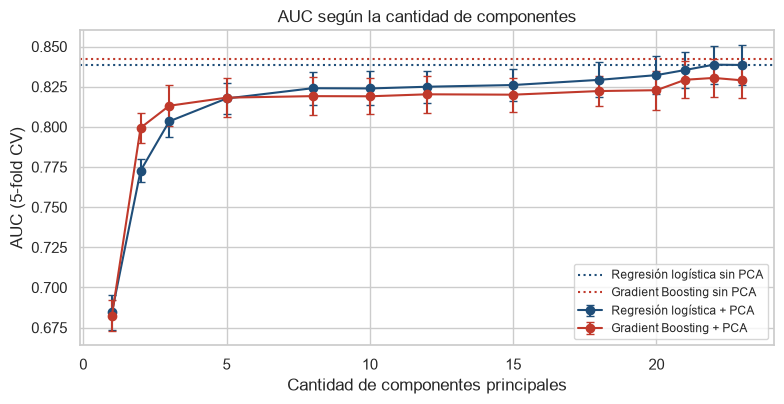

In [23]:
lista_componentes = [1, 2, 3, 5, 8, 10, 12, 15, 18, 20, 21, 22, rango]

# regresión logística + PCA (con el C que encontramos antes)
pipe_lr_pca = Pipeline([('preprocessor', preprocessor), ('scaler', StandardScaler()), ('pca', PCA(random_state=42)),
                        ('clf', LogisticRegression(max_iter=5000, C=CV_lr.best_params_['clf__C'],
                                                   class_weight=CV_lr.best_params_['clf__class_weight']))])
CV_lr_pca = GridSearchCV(pipe_lr_pca, param_grid={'pca__n_components': lista_componentes}, cv=cv, scoring='roc_auc', n_jobs=-1)
CV_lr_pca.fit(xtrain, ytrain)

# gradient boosting + PCA (con los hiperparámetros que encontramos antes)
pipe_gb_pca = Pipeline([('preprocessor', preprocessor), ('scaler', StandardScaler()), ('pca', PCA(random_state=42)),
                        ('clf', GradientBoostingClassifier(random_state=42,
                                                           n_estimators=CV_gb.best_params_['clf__n_estimators'],
                                                           learning_rate=CV_gb.best_params_['clf__learning_rate'],
                                                           max_depth=CV_gb.best_params_['clf__max_depth']))])
CV_gb_pca = GridSearchCV(pipe_gb_pca, param_grid={'pca__n_components': lista_componentes}, cv=cv, scoring='roc_auc', n_jobs=-1)
CV_gb_pca.fit(xtrain, ytrain)

plt.figure(figsize=(8, 4.2))
plt.errorbar(lista_componentes, CV_lr_pca.cv_results_['mean_test_score'], yerr=CV_lr_pca.cv_results_['std_test_score'],
             fmt='o-', capsize=3, color='#1f4e79', label='Regresión logística + PCA')
plt.axhline(CV_lr.best_score_, color='#1f4e79', ls=':', label='Regresión logística sin PCA')
plt.errorbar(lista_componentes, CV_gb_pca.cv_results_['mean_test_score'], yerr=CV_gb_pca.cv_results_['std_test_score'],
             fmt='o-', capsize=3, color='#c0392b', label='Gradient Boosting + PCA')
plt.axhline(CV_gb.best_score_, color='#c0392b', ls=':', label='Gradient Boosting sin PCA')
plt.xlabel('Cantidad de componentes principales')
plt.ylabel('AUC (5-fold CV)')
plt.title('AUC según la cantidad de componentes')
plt.legend(fontsize=8.5, loc='lower right')
plt.tight_layout()
plt.savefig('figuras/fig11_pca_auc.png', dpi=150, bbox_inches='tight')
plt.show()

Mirando el gráfico elegimos dos opciones para evaluar en test:
1. **23 componentes**: tienen toda la información, solo sacamos lo repetido.
2. **5 componentes**: en el gráfico se ve que con 5 componentes ya se llega a un AUC de ~0,82 y después sube despacio. Es una versión mucho más simple del modelo.

Entrenamos con todo train y evaluamos en test.

In [24]:
tabla_pca = []
for nombre, CV_pca, CV_original in [('Regresión logística', CV_lr_pca, CV_lr), ('Gradient Boosting', CV_gb_pca, CV_gb)]:
    medias = CV_pca.cv_results_['mean_test_score']

    # sin PCA (lo que ya teníamos)
    tabla_pca.append([nombre + ' sin PCA', 46, round(CV_original.best_score_, 3),
                      round(roc_auc_score(ytest, CV_original.predict_proba(xtest)[:, 1]), 3)])

    # con PCA: 23 componentes (toda la info) y 5 componentes (modelo simple, elegido mirando el grafico)
    for p in [23, 5]:
        modelo = CV_pca.best_estimator_.set_params(pca__n_components=p)
        modelo.fit(xtrain, ytrain)
        yproba = modelo.predict_proba(xtest)[:, 1]
        tabla_pca.append([nombre + ' + PCA (' + str(p) + ' comp, ' + str(round(varianza_acumulada[p - 1] * 100)) + '% var)', p,
                          round(medias[lista_componentes.index(p)], 3), round(roc_auc_score(ytest, yproba), 3)])

tabla_pca = pd.DataFrame(tabla_pca, columns=['Modelo', 'N° features', 'AUC CV', 'AUC test'])
tabla_pca

,Modelo,N° features,AUC CV,AUC test
0,Regresión logística sin PCA,46,0.839,0.835
1,"Regresión logística + PCA (23 comp, 100% var)",23,0.838,0.835
2,"Regresión logística + PCA (5 comp, 56% var)",5,0.818,0.811
3,Gradient Boosting sin PCA,46,0.842,0.847
4,"Gradient Boosting + PCA (23 comp, 100% var)",23,0.829,0.829
5,"Gradient Boosting + PCA (5 comp, 56% var)",5,0.818,0.820


**Conclusiones del PCA:**
- **Regresión logística + PCA con 23 componentes: da exactamente lo mismo que con las 46 features** (AUC 0,835 en test). Pasamos de 46 a 23 dimensiones **sin perder nada**, porque el PCA solo sacó la información repetida (y de paso la multicolinealidad). Tiene sentido: la logística sobre las componentes sigue siendo un modelo lineal de las variables originales.
- **Con solo 5 componentes (56% de la varianza)** el AUC en test baja a 0,811 en la logística y a 0,820 en el Gradient Boosting. Perdemos entre 0,02 y 0,03 de AUC, pero usando **9 veces menos variables** (5 en vez de 46).
- En el gráfico se ve que el AUC sigue subiendo un poco hasta la componente 23. O sea, **las componentes con poca varianza también ayudan a predecir**. Es la limitación del PCA: es **no supervisado**, busca las direcciones con más varianza y no las que mejor separan a los que se van. Por ejemplo, con 1 sola componente el AUC es 0,68, porque PC1 es "tiene internet o no", que no es lo más importante para el churn.
- **Gradient Boosting + PCA empeora incluso con 23 componentes** (0,829 contra 0,847). Los árboles cortan **por una variable a la vez** ("¿contrato mes a mes?", "¿tenure < 12?"). El PCA rota los ejes y mezcla todas las variables en cada componente, así que esos cortes simples se pierden.
- Además **se pierde interpretabilidad**: ya no podemos decir "el contrato mes a mes aumenta el riesgo", solo "la componente 2 aumenta el riesgo".

**En este problema el PCA no mejora la predicción**, porque 46 features son pocas para 5.634 clientes y no tenemos el problema de la maldición de la dimensionalidad. Lo que sí muestra es que **la dimensión real de los datos es la mitad de la aparente** (23 de 46).

# Conclusiones finales

1. **Se puede predecir el churn con buena capacidad**: el mejor modelo (Gradient Boosting) tiene **AUC = 0,847 en test**, muy por encima del azar (0,5), y la validación cruzada coincide con el test.
2. **Gradient Boosting fue el mejor**, pero Random Forest, la red neuronal y la **regresión logística** quedan prácticamente empatados (las diferencias son menores que el desvío entre folds). Para la empresa, la logística es una muy buena alternativa: casi lo mismo de desempeño y mucho más fácil de explicar.
3. **El umbral importa tanto como el modelo.** Con 0,5 detectamos la mitad de los que se van y sale más caro que ofrecerle la retención a todos. Con el umbral de costos (0,12) detectamos el 94% y logramos el menor costo (26% menos que ofrecer a todos), aunque la accuracy baje de 0,81 a 0,63.
4. **Perfil de riesgo** (lo que vimos en el EDA): cliente nuevo, contrato mes a mes, fibra óptica, cargo mensual alto, pago con cheque electrónico y sin seguridad ni soporte. Para Telco NN esto sugiere: incentivar contratos largos y débito automático, ofrecer seguridad y soporte en los primeros meses y revisar el precio y la calidad de la fibra.
5. **PCA**: los datos tienen dimensión real 23 sobre 46. La logística con 23 componentes da lo mismo; con menos componentes, o con árboles, el resultado empeora un poco. En este caso no hacía falta reducir dimensiones para predecir mejor.
6. **Limitaciones**: imputamos con la moda entre el 13% y el 17% de las variables demográficas y de contrato (se podría probar `IterativeImputer` o `KNNImputer`), los datos son de un solo momento y los costos son supuestos. Para mejorar haría falta información del comportamiento del cliente.